In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [2]:
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
})

# Change this to any saved result under output/
# npz_path = 'output/result_Mc5_R5_sddr_generic_logB2_50steps_32499951.npz' # HM waveform
npz_path = 'output/result_Mc50_R50_sddr_generic_logB2_50steps_27715448.npz' # outdated but smooth plot
data = np.load(npz_path)

n_Mc = len(np.unique(data['Mc']))
n_R = len(np.unique(data['R_orbit']))
Mc_array = np.unique(data['Mc'])
R_orbit_array = np.unique(data['R_orbit'])
snr_grid_1 = data['snr_1'].reshape((n_Mc, n_R))
snr_grid_2 = data['snr_2'].reshape((n_Mc, n_R))
y_Eins_1 = float(data['y_Eins_1'])
y_Eins_2 = float(data['y_Eins_2'])
print(f'Loaded {npz_path}: n_Mc={n_Mc}, n_R={n_R}, y=({y_Eins_1:g}, {y_Eins_2:g})')

Loaded output/result_Mc50_R50_sddr_generic_logB2_50steps_27715448.npz: n_Mc=50, n_R=50, y=(0.7, 0.2)


/tmp/ipykernel_418281/3097996118.py:36: RuntimeWarning: invalid value encountered in log10
  log10_snr_c = np.log10(snr_grid)


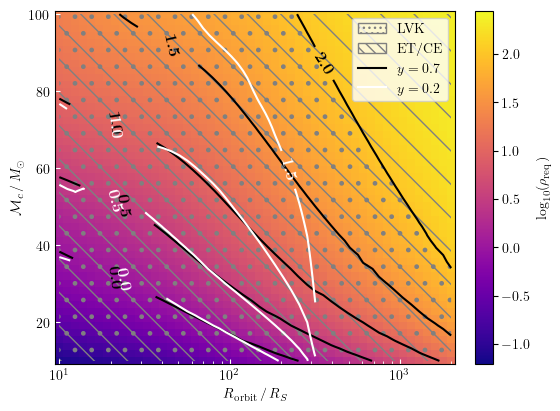

In [3]:
fig, ax = plt.subplots(1, 1, figsize=(5.5, 4), constrained_layout=True)
log10_snr = np.log10(snr_grid_1)
log10_snr = np.where(log10_snr < -3, np.nan, log10_snr)
ax.set_facecolor('lightgrey')
cmap = plt.cm.plasma.copy()
cmap.set_bad(color='lightgrey')
_min, _max = np.nanmin(log10_snr), np.nanmax(log10_snr)
midpoint = (_max + _min) / 2
half_range = (_max - _min) / 2 * 1.05
norm = colors.TwoSlopeNorm(vmin=midpoint - half_range, vcenter=midpoint, vmax=midpoint + half_range)

im = ax.pcolormesh(R_orbit_array, Mc_array, log10_snr, cmap=cmap, norm=norm, shading='nearest')

# Hatch regions reachable at given detector SNR
_shade_floor = float(np.nanmin(log10_snr)) - 1.0
for _level, _hatch, _edge in [
        (3.0, '\\', '0.5'),   # ET/CE: log10(rho_req) < 3
        (2.0, '.', '0.5'),      # LVK: log10(rho_req) < 2
]:
    _cs = ax.contourf(
        R_orbit_array, Mc_array, log10_snr,
        levels=[_shade_floor, _level], colors='none', hatches=[_hatch],
    )
    for _coll in getattr(_cs, 'collections', [_cs]):
        _coll.set_edgecolor(_edge)
        _coll.set_linewidth(0.0)

legend_handles = [
    Patch(facecolor='none', edgecolor='0.5', hatch='...', label=r'LVK'),
    Patch(facecolor='none', edgecolor='0.5', hatch='\\\\\\', label=r'ET/CE'),
]
for snr_grid, color, contour_label in zip(
        [snr_grid_1, snr_grid_2],
        ['black', 'white'],
        [rf'$y = {y_Eins_1:g}$', rf'$y = {y_Eins_2:g}$']):
    log10_snr_c = np.log10(snr_grid)
    cont_snrs = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5]
    cont = ax.contour(R_orbit_array, Mc_array, log10_snr_c, colors=[color], levels=cont_snrs)
    labels = {lvl: rf'\textbf{{{snr}}}' for lvl, snr in zip(cont.levels, cont_snrs)}
    ax.clabel(cont, fmt=labels, fontsize=12)
    legend_handles.append(Line2D([0], [0], color=color, linewidth=1.5, label=contour_label))
ax.legend(handles=legend_handles, loc='upper right', fontsize=10)
ax.tick_params(which='both', direction='in', colors='white', labelcolor='black')

ax.set_xscale('log')
ax.set_xlabel(r'$R_{\rm orbit}\,/\,R_S$')
ax.set_ylabel(r'$\mathcal{M}_c\,/\,M_\odot$')
fig.colorbar(im, ax=ax, label=r'$\log_{10}(\rho_{\rm req})$')
fig.savefig('plots/replot_test_RMcplot.pdf')
plt.show()